In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # no of cores you want to allow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # for 3D plotting

from sklearn.decomposition import PCA
from sklearn.manifold import LocallyLinearEmbedding
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics.cluster import contingency_matrix
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, confusion_matrix,
roc_curve, auc, silhouette_score, adjusted_rand_score)
from sklearn.preprocessing import normalize

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset

import cv2
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

In [2]:
# CONFIGURATION
use_rgb     = True
image_size  = (224, 224)
batch_size  = 32
device      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# TRANSFORMS
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406],
                         std=[0.229,0.224,0.225])
])

# DATASET DEFINITION
class ImageFolderDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths     = paths
        self.labels    = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = cv2.imread(self.paths[idx],
                         cv2.IMREAD_COLOR if use_rgb else cv2.IMREAD_GRAYSCALE)
        if use_rgb:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = self.transform(img)
        return img, self.labels[idx]

def collect_image_paths(root_dir):
    paths, labels = [], []
    for name, idx in [('pleasant',1), ('unpleasant',0)]:
        folder = os.path.join(root_dir, name)
        for fname in os.listdir(folder):
            paths.append(os.path.join(folder, fname))
            labels.append(idx)
    return paths, labels

# LOAD & SPLIT
all_paths, all_labels = collect_image_paths('train-images/train')
X_train_paths, X_val_paths, y_train, y_val = train_test_split(
    all_paths, all_labels,
    test_size=0.2,
    random_state=42,
    stratify=all_labels
)

train_ds = ImageFolderDataset(X_train_paths, y_train, transform)
val_ds   = ImageFolderDataset(X_val_paths,   y_val,   transform)
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

In [3]:
# FEATURE EXTRACTOR SETUP (EfficientNet-B0)
effnet = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT).to(device)
for p in effnet.parameters():
    p.requires_grad = False

feature_extractor = nn.Sequential(
    effnet.features,
    effnet.avgpool
).to(device)
# flattened feature dim:
feat_dim = effnet.classifier[1].in_features  # 1280

In [4]:
# EXTRACT FEATURES FUNCTION
def extract_features(loader):
    feature_extractor.eval()
    feats, labs = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            out = feature_extractor(imgs)        # (B,1280,1,1)
            out = out.flatten(1).cpu().numpy()   # → (B,1280)
            feats.append(out)
            labs.append(labels.numpy())
    return np.vstack(feats), np.concatenate(labs)

train_feats, train_labels = extract_features(train_loader)
val_feats,   val_labels   = extract_features(val_loader)

pca → 2 dims, explained variance ratio: 0.234
pca → 3 dims, explained variance ratio: 0.285
pca → 5 dims, explained variance ratio: 0.356
pca → 10 dims, explained variance ratio: 0.469
pca → 20 dims, explained variance ratio: 0.589


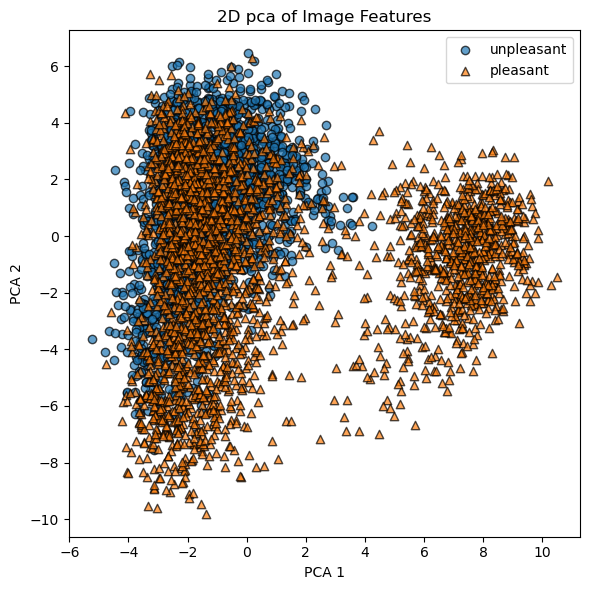

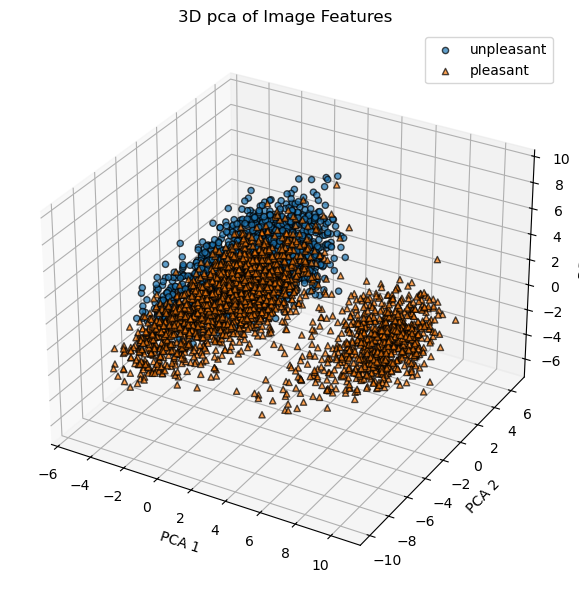

lle → 2 dims
lle → 3 dims
lle → 5 dims
lle → 10 dims
lle → 20 dims


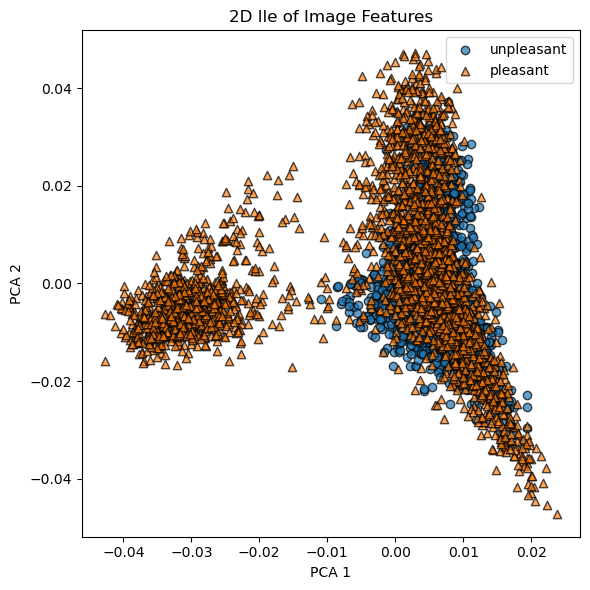

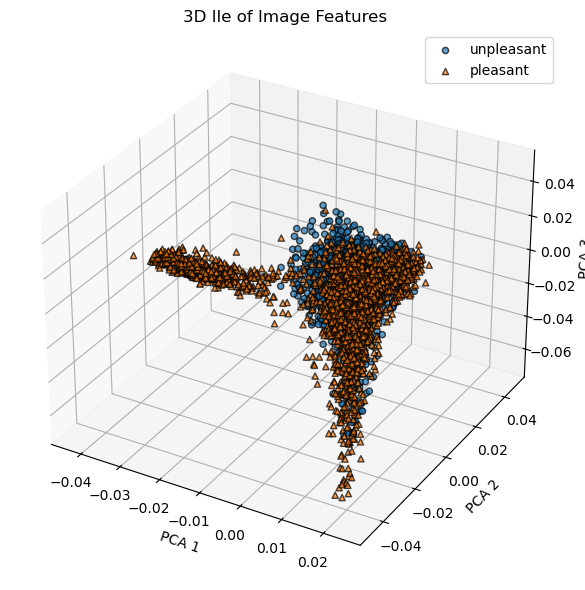

autoencoders → 2 dims
autoencoders → 3 dims
autoencoders → 5 dims
autoencoders → 10 dims
autoencoders → 20 dims


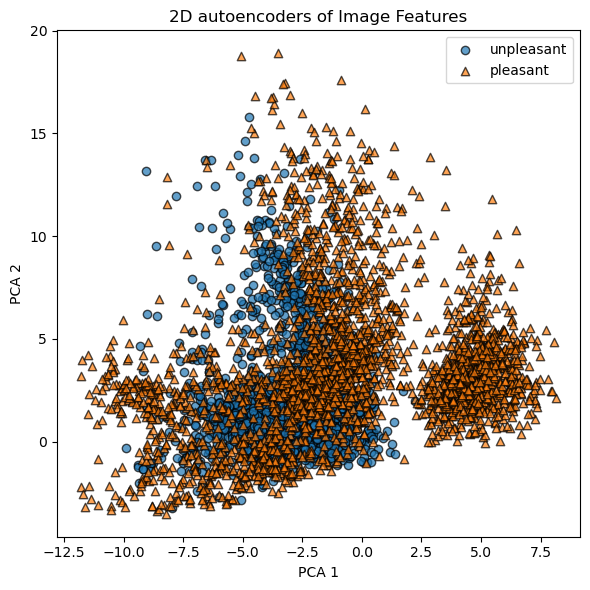

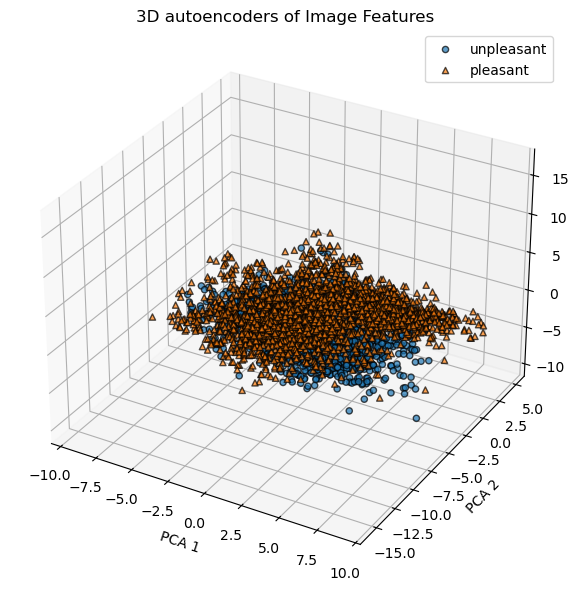

In [5]:
dims = [2, 3, 5, 10, 20]
models = {}
transforms = {}
methods = ['pca','lle','autoencoders']

class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dims, latent_dim):
        super().__init__()
        h1, h2 = hidden_dims
        # encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, h1),
            nn.ReLU(True),
            nn.Linear(h1, h2),
            nn.ReLU(True),
            nn.Linear(h2, latent_dim),
        )
        # decoder (mirror of encoder)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, h2),
            nn.ReLU(True),
            nn.Linear(h2, h1),
            nn.ReLU(True),
            nn.Linear(h1, input_dim),
            nn.Sigmoid(),  # if features are normalized otherwise remove
        )
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)
        
for methodz in methods:
    for M in dims:
        if methodz == 'pca':
            method = PCA(n_components=M, random_state=42)
        elif methodz =='lle':
            method = LocallyLinearEmbedding(n_components=M, n_neighbors=200, random_state=42)    
        else:
            # prepare data loader for feature-only dataset 
            feat_tensor = torch.from_numpy(train_feats).float()
            ae_ds = TensorDataset(feat_tensor)
            ae_loader = DataLoader(ae_ds, batch_size=64, shuffle=True)

            # build model
            ae = Autoencoder(
                input_dim=feat_dim,
                hidden_dims=[256, 128],
                latent_dim=M
            ).to(device)

            # training setup
            criterion = nn.MSELoss()
            optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
            num_epochs = 20

            # train
            ae.train()
            for epoch in range(num_epochs):
                running_loss = 0.0
                for (batch_x,) in ae_loader:
                    batch_x = batch_x.to(device)
                    optimizer.zero_grad()
                    recon = ae(batch_x)
                    loss = criterion(recon, batch_x)
                    loss.backward()
                    optimizer.step()
                    running_loss += loss.item() * batch_x.size(0)

            # encode the full train set
            ae.eval()
            with torch.no_grad():
                latent = ae.encoder(feat_tensor.to(device)).cpu().numpy()

            Xr = latent
            method = ae  

        if methodz in ('pca','lle'):
            Xr = method.fit_transform(train_feats)
        models[M] = method
        transforms[methodz,M] = Xr
        if methodz == 'pca':
            var_ratio = method.explained_variance_ratio_.sum()
            print(f"{methodz} → {M} dims, explained variance ratio: {var_ratio:.3f}")
        else:
            print(f"{methodz} → {M} dims")

    # 2D scatter (M=2) with different markers per class
    X2 = transforms[methodz,2]
    plt.figure(figsize=(6,6))
    for label, color, marker, name in [
        (0, 'C0', 'o', 'unpleasant'),
        (1, 'C1', '^', 'pleasant')
    ]:
        idx = train_labels == label
        plt.scatter(
            X2[idx,0], X2[idx,1],
            c=color, marker=marker,
            label=name, alpha=0.7, edgecolors='k'
        )
    plt.xlabel('PCA 1')
    plt.ylabel('PCA 2')
    plt.title(f'2D {methodz} of Image Features')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 3D scatter (M=3) with different markers per class
    X3 = transforms[methodz,3]
    fig = plt.figure(figsize=(7,6))
    ax = fig.add_subplot(111, projection='3d')
    for label, color, marker, name in [
        (0, 'C0', 'o', 'unpleasant'),
        (1, 'C1', '^', 'pleasant')
    ]:
        idx = train_labels == label
        ax.scatter(
            X3[idx,0], X3[idx,1], X3[idx,2],
            c=color, marker=marker,
            label=name, alpha=0.7, edgecolors='k'
        )
    ax.set_xlabel('PCA 1')
    ax.set_ylabel('PCA 2')
    ax.set_zlabel('PCA 3')
    ax.set_title(f'3D {methodz} of Image Features')
    ax.legend()
    plt.tight_layout()
    plt.show()

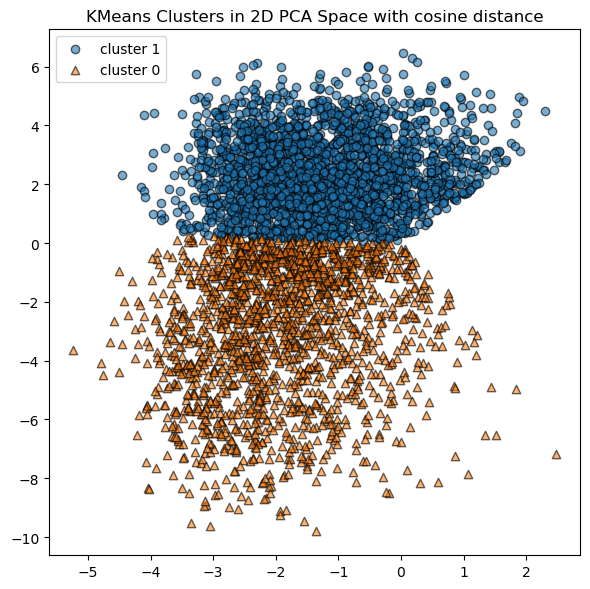

In [6]:
# K-MEANS CLUSTERING IN PCA SPACES
for M in dims:
    Xp = transforms['pca',M]
    Xc = normalize(Xp, norm='l2', axis=1)

    # fit K-Means with k=3
    kmeans = KMeans(n_clusters=3, random_state=42)
    clusters = kmeans.fit_predict(Xc)

    # visualize for 2D
    if M == 2:
        fig, ax = plt.subplots(figsize=(6,6))
        for cid, marker, col in [(1,'o','C0'), (0,'^','C1')]:
            idx = clusters == cid
            ax.scatter(
                Xp[idx,0], Xp[idx,1],
                marker=marker, c=col,
                label=f'cluster {cid}',
                alpha=0.6, edgecolors='k'
            )
        ax.set_title('KMeans Clusters in 2D PCA Space with cosine distance')
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.legend()
        plt.tight_layout()
        plt.show()



In [7]:
def purity_score(y_true, y_pred):
    cm = contingency_matrix(y_true, y_pred)
    return np.sum(np.max(cm, axis=0)) / np.sum(cm)

Ks = list(range(2,11))

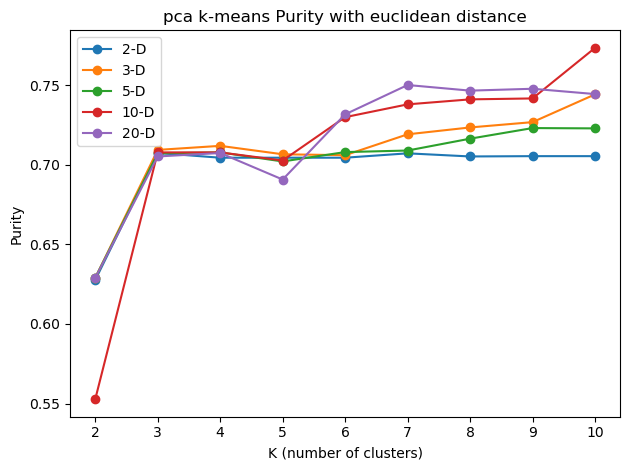

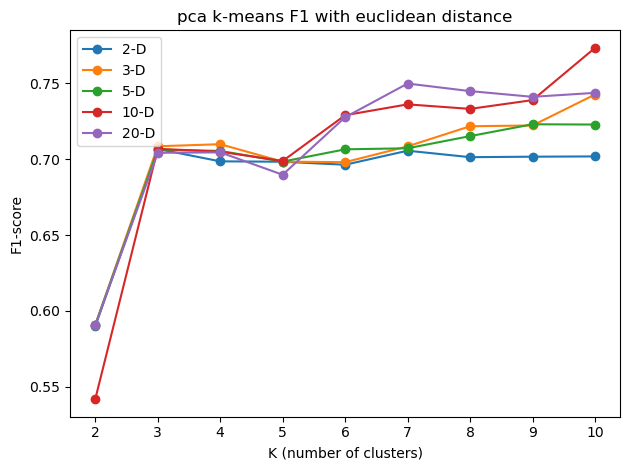

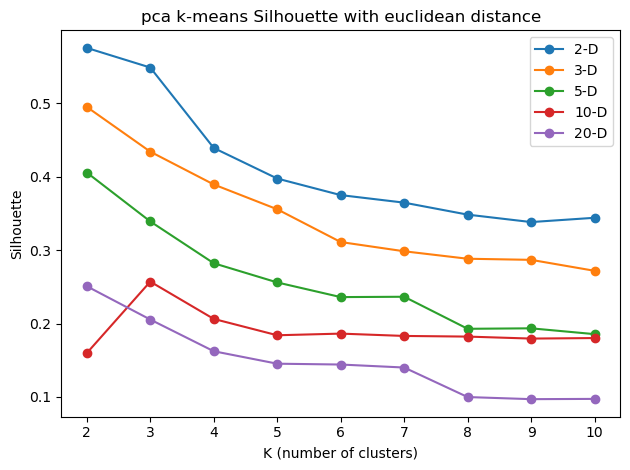

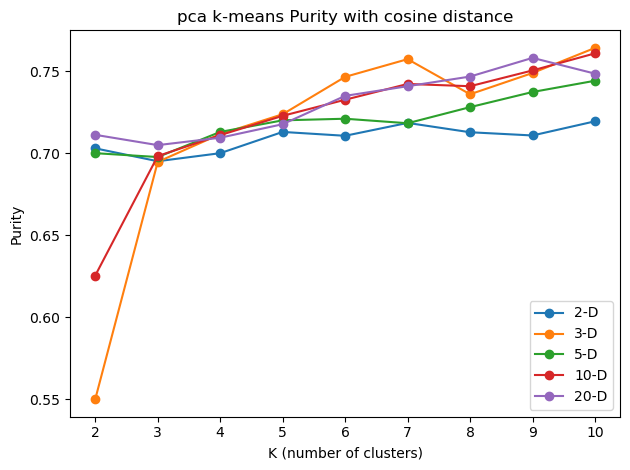

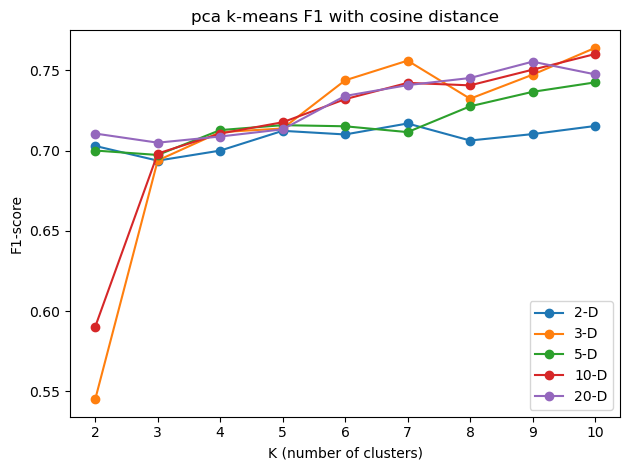

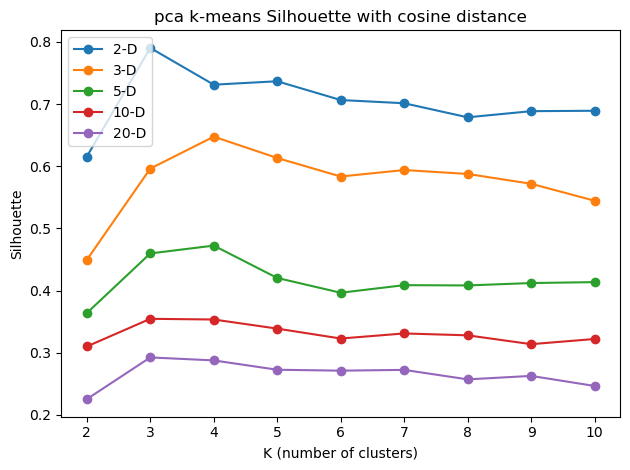

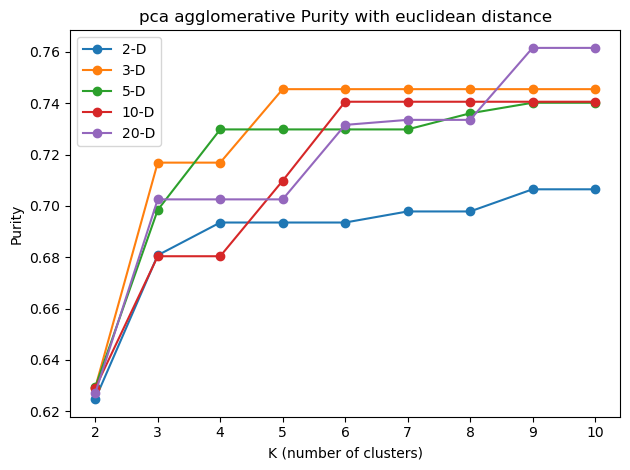

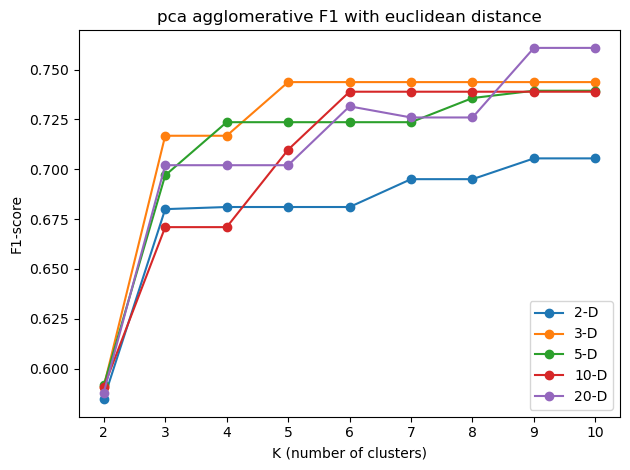

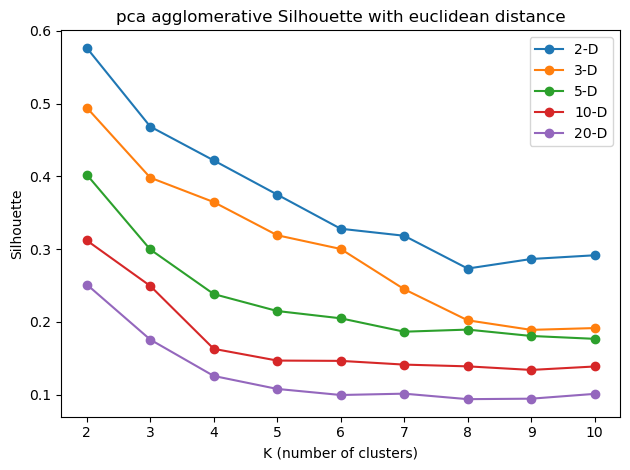

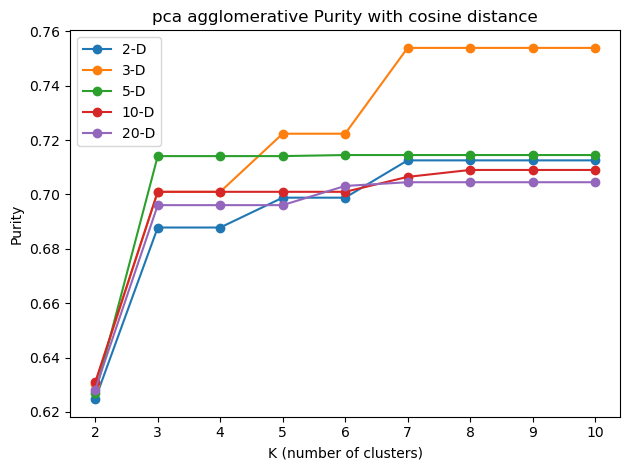

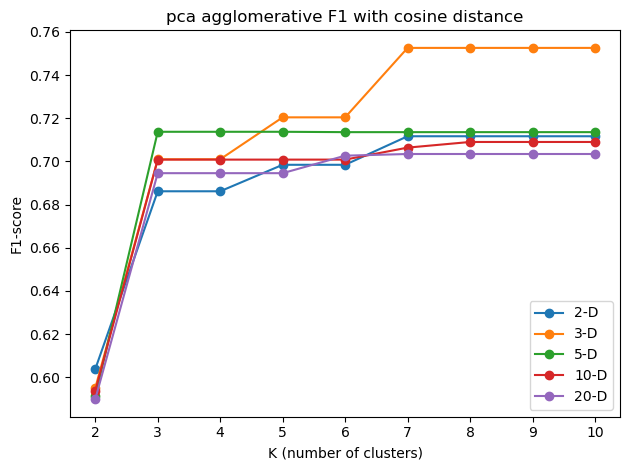

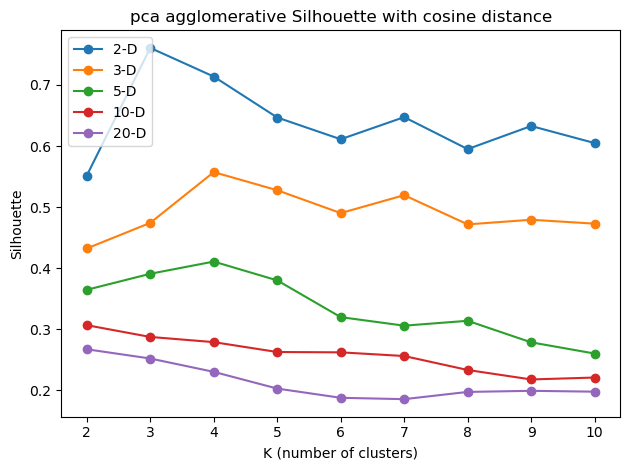

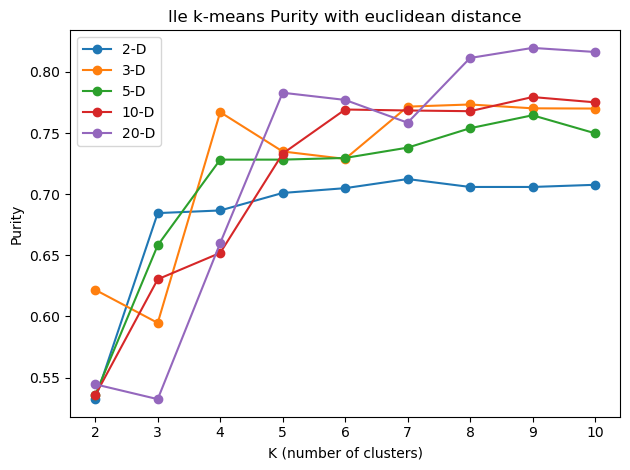

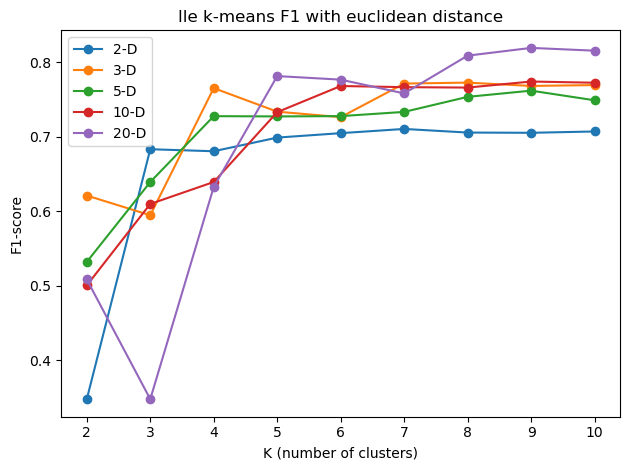

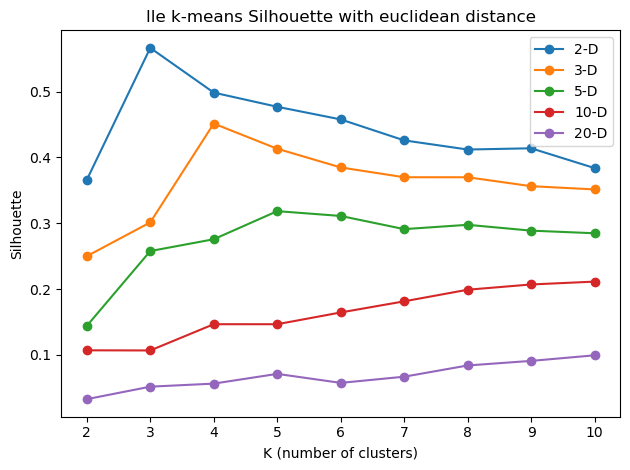

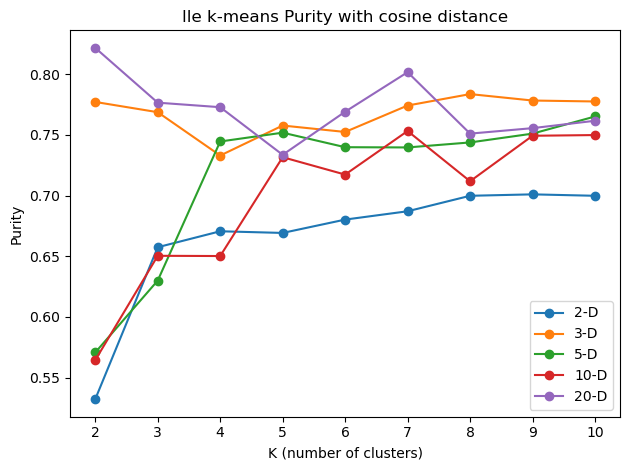

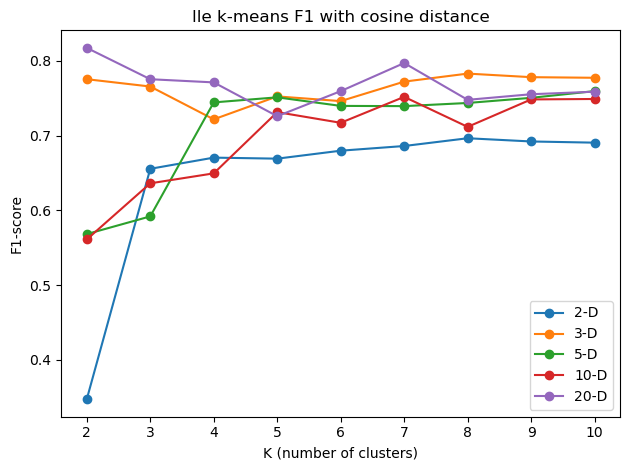

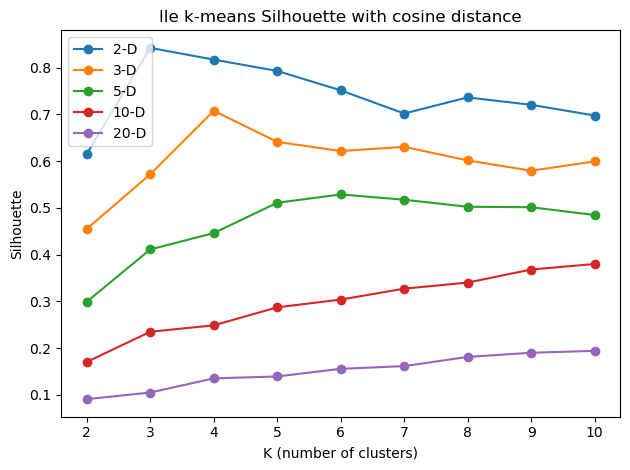

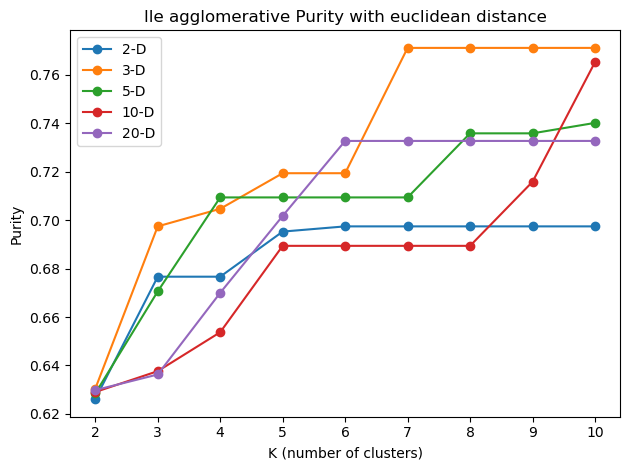

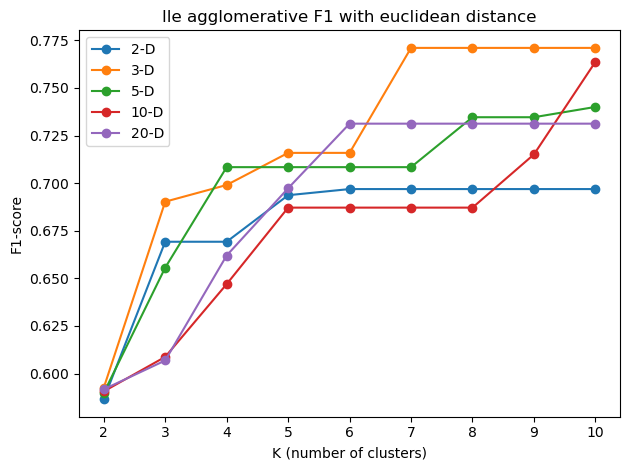

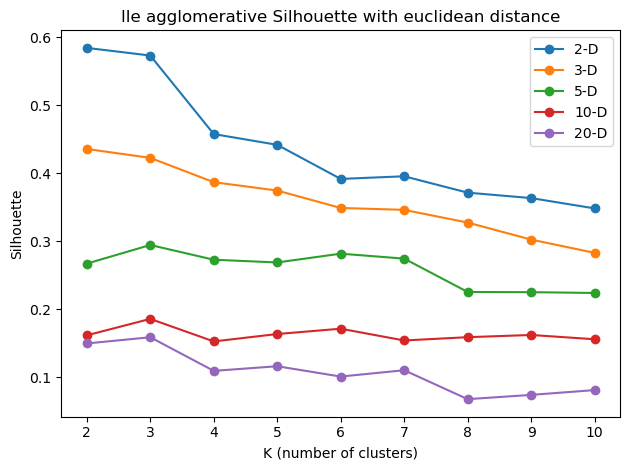

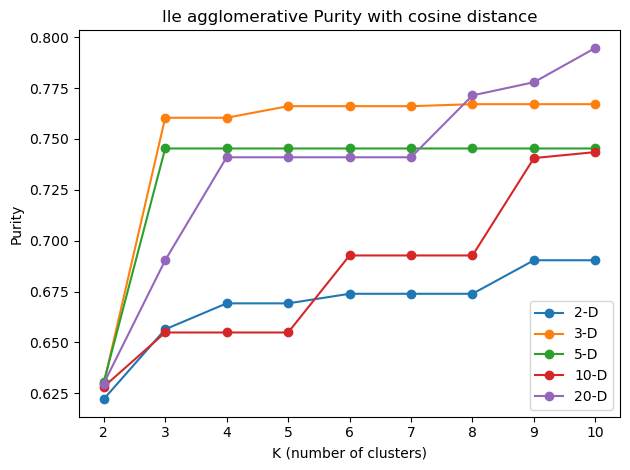

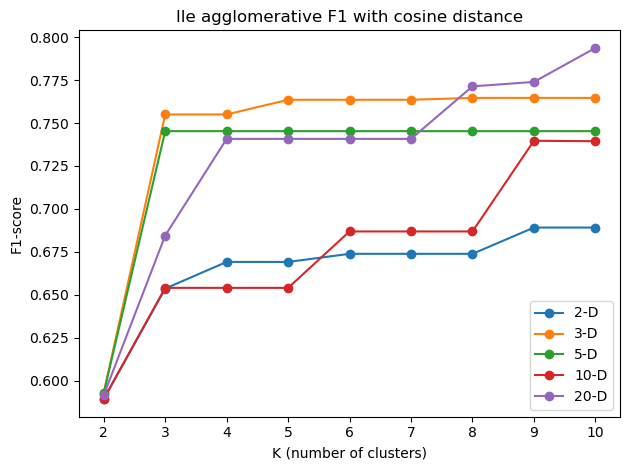

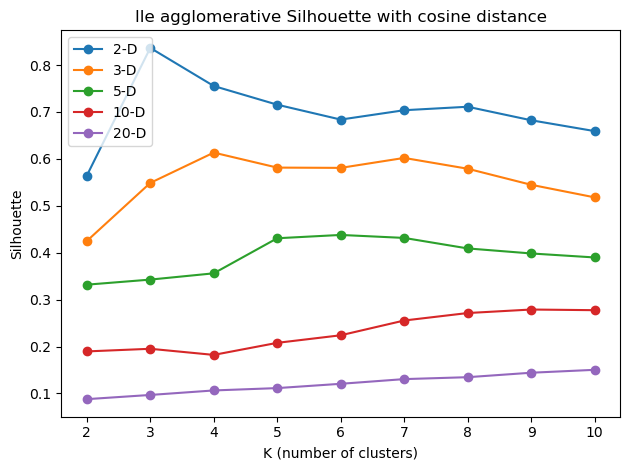

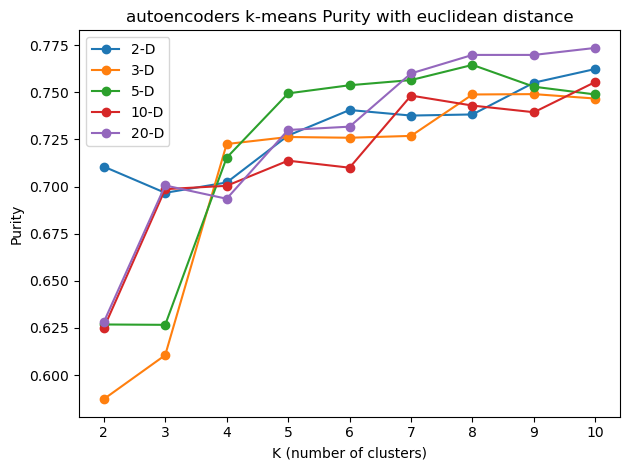

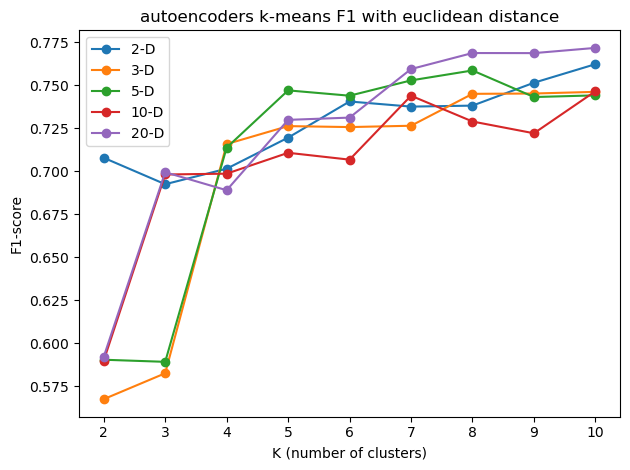

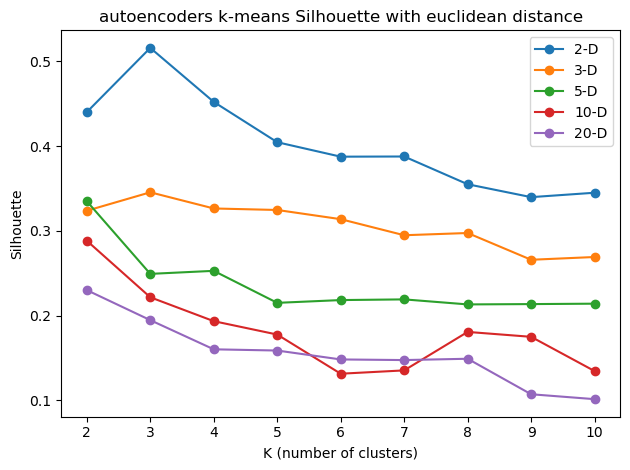

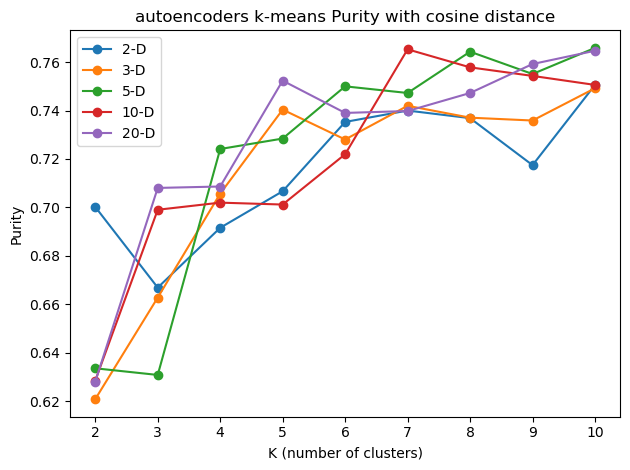

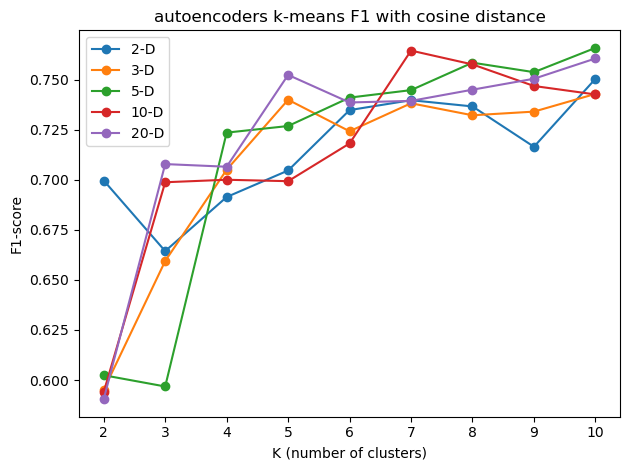

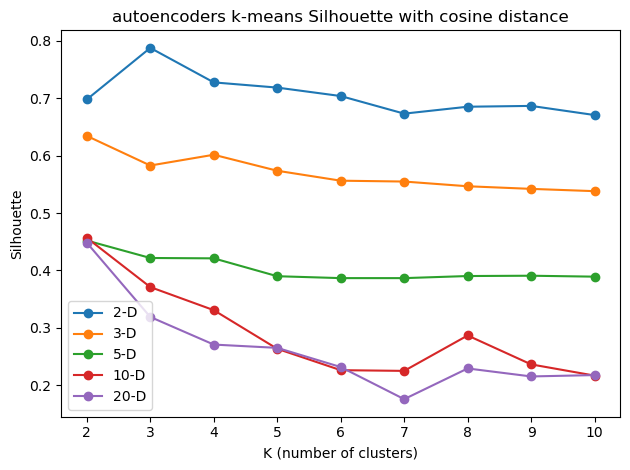

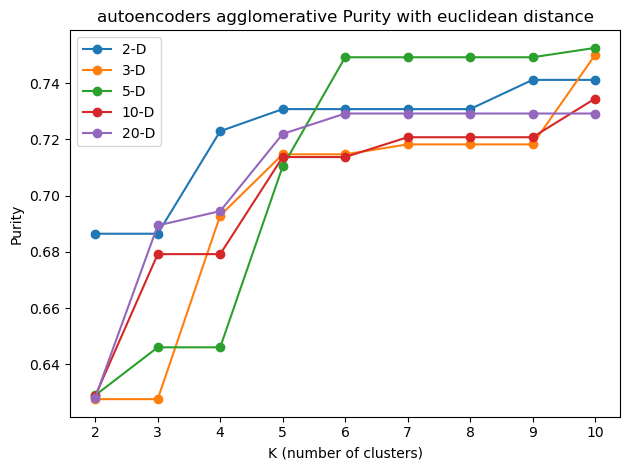

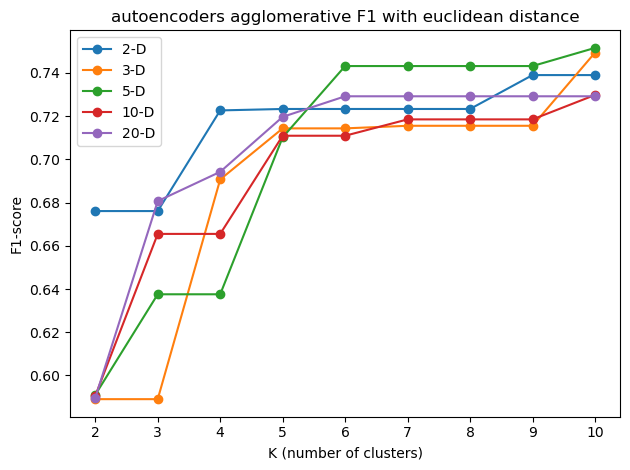

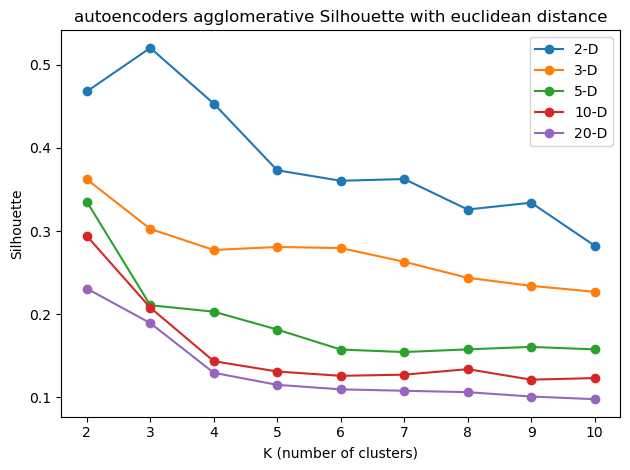

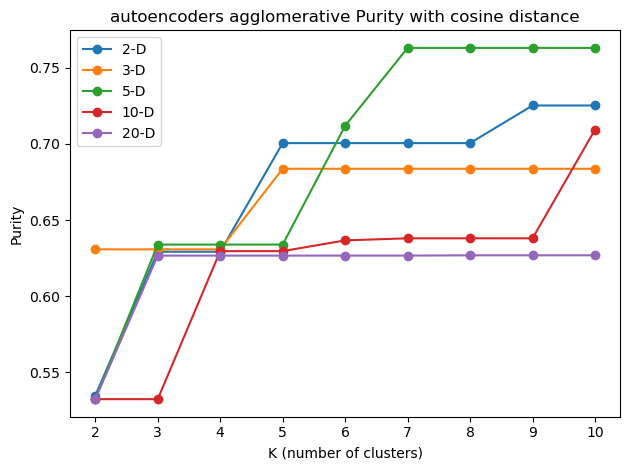

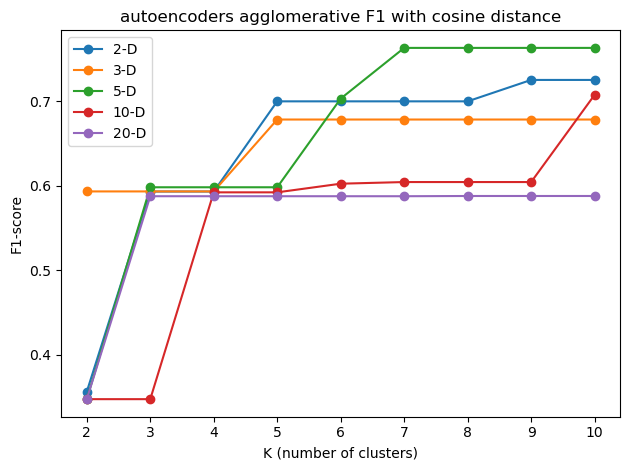

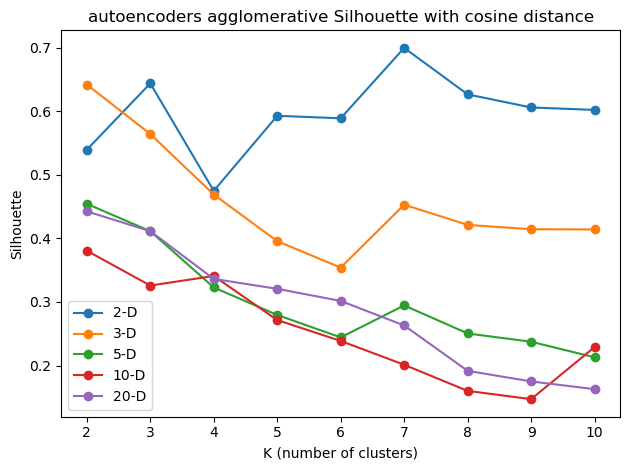

In [8]:
distance=['euclidean','cosine']
clusters=['k-means','agglomerative']

for methodz in methods:
    for cluster in clusters:
        for d in distance:
            metrics = {m: {'purity': [], 'f1': [], 'silhouette': []} for m in dims}
            for M in dims:
                Xp = transforms[methodz,M]
                if d == 'cosine':
                    Xc = normalize(Xp, norm='l2', axis=1)
                else:
                    Xc = Xp
                for K in Ks:
                    if cluster == 'k-means':
                        cl = KMeans(n_clusters=K, random_state=42)
                    else:
                        if d == 'euclidean':
                            cl = AgglomerativeClustering(n_clusters=K,linkage='ward',compute_distances=True)
                        else:
                            cl = AgglomerativeClustering(n_clusters=K,linkage='average',metric='cosine',compute_distances=True)
                    preds = cl.fit_predict(Xc)
                    pur   = purity_score(train_labels, preds)
                    sil   = silhouette_score(Xc, preds, metric=d)
                    # map clusters -> majority class for F1
                    cm      = contingency_matrix(train_labels, preds)
                    mapping = np.argmax(cm, axis=0)
                    mapped  = np.array([mapping[c] for c in preds])
                    f1m     = f1_score(train_labels, mapped, average='macro')

                    metrics[M]['purity'].append(pur)
                    metrics[M]['f1'].append(f1m)
                    metrics[M]['silhouette'].append(sil)
        

            # plot each metric
            for metric_name in ['purity', 'f1', 'silhouette']:
                plt.figure()
                for M in dims:
                    plt.plot(Ks, metrics[M][metric_name], marker='o', label=f'{M}-D')
                plt.xlabel('K (number of clusters)')
                if metric_name=='f1':
                    plt.ylabel('F1-score')
                else:
                    plt.ylabel(metric_name.capitalize())
                plt.title(f'{methodz} {cluster} {metric_name.capitalize()} with {d} distance')
                plt.xticks(Ks)
                plt.legend()
                plt.tight_layout()
                plt.show()